In [1]:
import numpy as np 
import pandas as pd 

In [2]:
df = pd.read_csv('titanic.csv')

In [3]:
df.head()

,Cabin,Ticket,number,Survived
0,NaN,A/5 21171,5,0
1,C85,PC 17599,3,1
2,NaN,STON/O2. 3101282,6,1
3,C123,113803,3,1
4,NaN,373450,A,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Cabin     204 non-null    object
 1   Ticket    891 non-null    object
 2   number    891 non-null    object
 3   Survived  891 non-null    int64 
dtypes: int64(1), object(3)
memory usage: 28.0+ KB


In [6]:
df.isnull().sum()

Cabin       687
Ticket        0
number        0
Survived      0
dtype: int64

In [9]:
df['number'].unique()

array(['5', '3', '6', 'A', '2', '1', '4'], dtype=object)

Text(0.5, 1.0, 'Passenger travelling with')

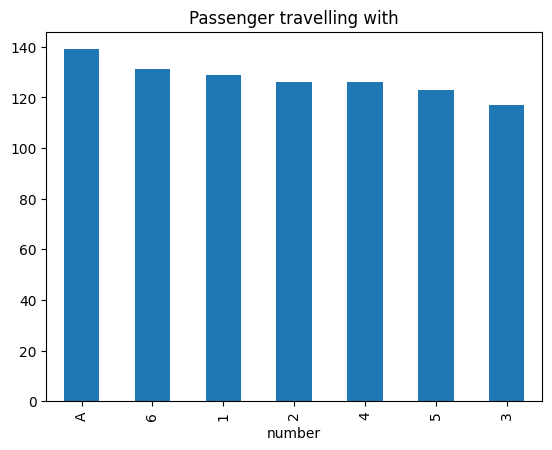

In [11]:
fig = df['number'].value_counts().plot.bar()
fig.set_title('Passenger travelling with')

In [12]:
# extract numerical part 
df['number_numerical'] = pd.to_numeric(df['number'],errors='coerce',downcast='integer')

In [13]:
# extract categorical part 
df['number_categorical'] = np.where(df['number_numerical'].isnull(),df['number'],np.nan)

In [14]:
df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical
0,NaN,A/5 21171,5,0,5.0,NaN
1,C85,PC 17599,3,1,3.0,NaN
2,NaN,STON/O2. 3101282,6,1,6.0,NaN
3,C123,113803,3,1,3.0,NaN
4,NaN,373450,A,0,NaN,A


In [17]:
df['Cabin'].value_counts()

Cabin
B96 B98        4
G6             4
C23 C25 C27    4
C22 C26        3
F33            3
              ..
E34            1
C7             1
C54            1
E36            1
C148           1
Name: count, Length: 147, dtype: int64

In [18]:
df['Cabin_num'] = df['Cabin'].str.extract("(\d+)") # Capturing numerical part
df['Cabin_cat'] = df['Cabin'].str[0] # Captures the first Letter

In [19]:
df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical,Cabin_num,Cabin_cat
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN
1,C85,PC 17599,3,1,3.0,NaN,85,C
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN
3,C123,113803,3,1,3.0,NaN,123,C
4,NaN,373450,A,0,NaN,A,NaN,NaN


In [22]:
# Extract the Last bit of ticket as number 
df['ticket_num'] = df['Ticket'].apply(lambda s : s.split()[-1])
df['ticket_num'] = pd.to_numeric(df['ticket_num'],
                               errors = 'coerce', 
                               downcast = 'integer')

In [23]:
# Extract the first part of ticket as category 
df['ticket_cat'] = df['Ticket'].apply(lambda s : s.split()[0])
df['ticket_cat'] = np.where(df['ticket_cat'].str.isdigit(),np.nan,df['ticket_cat'])

In [24]:
df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical,Cabin_num,Cabin_cat,ticket_num,ticket_cat
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN,21171.0,A/5
1,C85,PC 17599,3,1,3.0,NaN,85,C,17599.0,PC
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN,3101282.0,STON/O2.
3,C123,113803,3,1,3.0,NaN,123,C,113803.0,NaN
4,NaN,373450,A,0,NaN,A,NaN,NaN,373450.0,NaN
